In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../data/raw/student-por.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
print(df.shape)
df.info()

(649, 33)
<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  

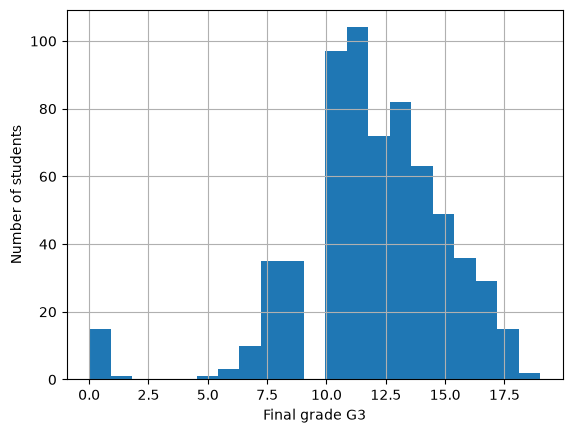

In [3]:
df["G3"].describe()
df["G3"].hist(bins=21)
plt.xlabel("Final grade G3")
plt.ylabel("Number of students")
plt.show()

In [4]:
print((df["G3"] == 0).sum(), "students with G3 = 0")
print((df["G3"] < 10).sum(), "students failing (G3 < 10)")
df[df["G3"] == 0][["G1", "G2", "G3", "absences"]]

15 students with G3 = 0
100 students failing (G3 < 10)


,G1,G2,G3,absences
163,11,9,0,0
440,7,0,0,0
519,8,7,0,0
563,7,0,0,0
567,4,0,0,0
583,8,6,0,0
586,8,8,0,0
597,9,0,0,0
603,5,0,0,0
605,5,0,0,0


In [5]:
df[["G1", "G2", "G3"]].corr()


,G1,G2,G3
G1,1.000000,0.864982,0.826387
G2,0.864982,1.000000,0.918548
G3,0.826387,0.918548,1.000000


In [6]:
for col in df.select_dtypes("object").columns:
    print(col, df[col].unique())


school <StringArray>
['GP', 'MS']
Length: 2, dtype: str
sex <StringArray>
['F', 'M']
Length: 2, dtype: str
address <StringArray>
['U', 'R']
Length: 2, dtype: str
famsize <StringArray>
['GT3', 'LE3']
Length: 2, dtype: str
Pstatus <StringArray>
['A', 'T']
Length: 2, dtype: str
Mjob <StringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str
Fjob <StringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str
reason <StringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str
guardian <StringArray>
['mother', 'father', 'other']
Length: 3, dtype: str
schoolsup <StringArray>
['yes', 'no']
Length: 2, dtype: str
famsup <StringArray>
['no', 'yes']
Length: 2, dtype: str
paid <StringArray>
['no', 'yes']
Length: 2, dtype: str
activities <StringArray>
['no', 'yes']
Length: 2, dtype: str
nursery <StringArray>
['yes', 'no']
Length: 2, dtype: str
higher <StringArray>
['yes', 'no']
Length: 2, dtype: str
internet <StringArray>
['n

/var/folders/nm/hssynf9j6fj5fj4sprklqy5m0000gn/T/ipykernel_76012/379249867.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object").columns:


## Cleaning decisions

- **G1 and G2 are dropped**: they are only known during the year, but our tool is used at the start of the year (leakage).
- **The 15 students with G3 = 0 are dropped**: all of them have 0 absences, so they most likely never sat the final exam. The tool predicts the grade of students who sit the exam.

In [7]:
%load_ext autoreload
%autoreload 2

from student_performance.data import DatasetLoader

In [8]:
loader = DatasetLoader("../data/raw/student-por.csv", drop_columns=["G1", "G2"])
df_clean = loader.clean(loader.load())
X_train, X_test, y_train, y_test = loader.split(df_clean)

print("Cleaned:", df_clean.shape)
print("Train:", X_train.shape, " Test:", X_test.shape)

Cleaned: (634, 31)
Train: (507, 30)  Test: (127, 30)


In [9]:
print("Fail rate in train:", round((y_train < 10).mean(), 3))
print("Fail rate in test: ", round((y_test < 10).mean(), 3))

Fail rate in train: 0.134
Fail rate in test:  0.134


The split is done once, 80/20, stratified on pass/fail so both sets keep the same fail rate (13.4 %). From here on, the test set is not touched until the final evaluation.